# An electro-optic modulator: x-cut thin-film lithium niobate, push-pull

**Question.** A 700 nm film of x-cut lithium niobate on oxide is etched 400 nm deep
into two ridges, 900 nm wide. Gold electrodes on the film form a ground-signal-ground
line, with one ridge in each 3.5 µm gap: a voltage on the signal electrode puts opposite
fields across the two ridges. The crystal's index moves with the field (the Pockels
effect), so the two arms of a Mach-Zehnder interferometer built on them shift in
opposite directions. How many volt-centimetres does the pair need for a $\pi$ phase
difference? Where in the section does the field do its work? And which electrode gap
and ridge width need the fewest volt-centimetres, with the electrodes kept far enough
from the light?

The section is the push-pull modulator of Wang et al., *Optics Express* **26**, 1547
(2018), who measured $V_\pi L = 1.8$ V·cm. The comparison is part of this page.

The chain from voltage to phase has two steps, each one call:

1. {py:class}`gfem.Electrostatic`: the static potential with 1 V on the signal
   electrode and the grounds at 0 V, and the line's capacitance per length.
2. {py:func}`gfem.electro_optic_shift`: the change of each arm's guided-mode index per
   volt, through the crystal's electro-optic tensor.

**Assumptions.** The paper states the film, the etch, the ridge width, the gap and the
oxide cladding. The rest are this page's choices:

| item | value |
| --- | --- |
| sidewalls | vertical (real etched ridges lean at 60-75°) |
| buried oxide | 2 µm, the substrate under it left out |
| cladding | oxide up to 1 µm above the ridge tops, air above |
| electrodes | 0.2 µm thick on the film; signal and grounds 4 µm wide |
| static permittivity | crystal $(44, 44, 27.9)$ on its axes, oxide 3.9 |
| optical indices at 1.55 µm | $n_o = 2.2111$, $n_e = 2.1376$, oxide 1.444 |
| electro-optic tensor | clamped, $r_{13} = 9.6$, $r_{22} = 6.8$, $r_{33} = 30.9$, $r_{51} = 32.6$ pm/V |

- **A cross-section.** Nothing varies along the guide: the field is the one at DC, and
  travelling-wave effects (velocity matching, RF loss) are outside the page.
- **First order in the field.** The guided mode is solved once and held constant; the
  index change is linear in the voltage.

In [1]:
import time

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from scipy.constants import c, epsilon_0
from scipy.optimize import brentq, minimize
from tfln_section import tfln_section

import gfem
from gfem.shape import boundary_morph

um = 1e-6
WAVELENGTH = 1.55 * um
F0 = c / WAVELENGTH  # 193.4 THz
N_O, N_E, N_OXIDE = 2.2111, 2.1376, 1.444
R13, R22, R33, R51 = 9.6e-12, 6.8e-12, 30.9e-12, 32.6e-12  # m/V
tic = time.perf_counter()

## The section

{download}`tfln_section.py` builds the meshes with netgen, which ships with NGSolve:
it glues the section's rectangles, meshes them, writes a gmsh file with the region and
edge names, and reads it back with {py:meth}`gfem.Mesh.from_gmsh_cross_section`. The
section lies in the $(x, y)$ plane, $y$ up, $y = 0$ at the bottom of the film, and the
guide runs along $z$. Its regions are `"box"`, `"slab"` (the 300 nm of film left
after the etch), the ridges `"ridge_a"` (right, $x > 0$) and `"ridge_b"` (left),
`"cladding"`, `"air"`, and the electrodes `"signal"`, `"ground_r"` and `"ground_l"`.
The triangles are 60 nm in the ridges, 80 nm in the film and 100 nm in the
electrodes.

The helper makes three meshes at each gap and width. `static` is the whole section,
for the electrostatic solve. `window_a` and `window_b` are each ridge's
{term}`optical window`: the ridge and the film, oxide and cladding around it, out to the
electrodes' inner edges, where the field the mode feels is strongest. Every mesh
shares one slab thickness, so the windows' elements lie inside the static mesh.

The crystal appears in two models with one set of axes. x-cut means the crystal's
$x$ axis is the film normal, $y$; light runs along the crystal's $y$; and the
crystal's $z$, the axis of the strongest coefficient $r_{33}$, lies across the gaps,
along $x$. The electrostatic model gives the crystal its static permittivity and
leaves the electrodes out of the solve (`excluded={"em": [...]}`): their surfaces
carry the potentials. The optical windows give it its optical permittivity and the
contracted {term}`electro-optic tensor` of class $3m$, rows $xx, yy, zz, yz, xz, xy$ in
the crystal's frame.

In [2]:
# x-cut: crystal x up (y), crystal y along the guide (z), crystal z across the gaps (x)
AXES = ((0.0, 1.0, 0.0), (0.0, 0.0, 1.0), (1.0, 0.0, 0.0))
ELECTRODES = ["signal", "ground_r", "ground_l"]


def tensor_3m(r13, r22, r33, r51):
    # The contracted tensor of class 3m: rows xx yy zz yz xz xy, columns x y z.
    return jnp.array(
        [
            [0.0, -r22, r13],
            [0.0, r22, r13],
            [0.0, 0.0, r33],
            [0.0, r51, 0.0],
            [r51, 0.0, 0.0],
            [-r22, 0.0, 0.0],
        ]
    )


R_LN = tensor_3m(R13, R22, R33, R51)
LN_STATIC = gfem.Material(eps_r=(44.0, 44.0, 27.9), axes=AXES, name="LN (static)")
OXIDE_STATIC = gfem.Material(eps_r=3.9, name="oxide (static)")
LN_OPTICAL = gfem.Material(
    eps_r=(N_O**2, N_O**2, N_E**2), axes=AXES, electro_optic_tensor=R_LN, name="LN"
)
OXIDE = gfem.Material(eps_r=N_OXIDE**2, name="oxide")


def static_model(mesh):
    # The whole section at DC; the electrodes are left out of the solve.
    materials = {
        "air": gfem.Material(),
        "cladding": OXIDE_STATIC,
        "box": OXIDE_STATIC,
        "slab": LN_STATIC,
        "ridge_a": LN_STATIC,
        "ridge_b": LN_STATIC,
        **{name: gfem.Material() for name in ELECTRODES},
    }
    return gfem.Model(mesh, materials=materials, excluded={"em": ELECTRODES})


def window_model(mesh, crystal=LN_OPTICAL):
    # One arm's optical window at 1.55 um; its mode on the end face "front".
    materials = {"cladding": OXIDE, "box": OXIDE, "slab": crystal, "ridge": crystal}
    return gfem.Model(mesh, materials=materials, ports=[gfem.WavePort("arm", "front")])


DRIVE = gfem.Electrostatic({"signal": ["signal_s"]}, ground=["ground_s"])
OPTIONS = gfem.SolverOptions(order=2)

section = tfln_section(gap=3.5 * um, width=0.9 * um)
static = static_model(section.static)
window_a, window_b = window_model(section.window_a), window_model(section.window_b)
section.static

Mesh(8074 nodes, 23724 tetrahedra, volumes=['cladding', 'slab', 'ground_l', 'ridge_b', 'ground_r', 'signal', 'ridge_a', 'air', 'box'], surfaces=['clad_if', 'ln_if', 'ground_s', 'ridge_a_s', 'signal_s', 'ridge_b_s', 'bottom', 'front', 'back'], length_unit='um', section_thickness=1e-07 m)

## The static field

{py:class}`gfem.Electrostatic` holds the signal electrode's outline (`"signal_s"`) at
1 V and the grounds' (`"ground_s"`) at 0 V. The order-2 solve resolves the field's
gradient across the thin film. The same solve gives the capacitance the drive sees,
per metre of electrode on a cross-section.

In [3]:
es = gfem.solve(static, DRIVE, options=OPTIONS)
potential = es.potential["signal"]
c_per_length = float(es.capacitance_per_length[0, 0])  # F/m
print(f"capacitance per length: {1e12 * c_per_length:.1f} pF/m")

capacitance per length: 96.9 pF/m


The field across the section at 1 V, $|E_\mathrm{s}|$ with arrows along it. It is
read from the potential by central differences of 1 nm. Between the electrodes it
runs sideways, from the signal to each ground: towards $+x$ through ridge a and
towards $-x$ through ridge b. The crystal's static permittivity along $z$ (27.9) is
seven times the oxide's, so the field in the crystal is weaker than in the oxide
above it: in ridge a's centre it is 0.14 V/µm, half the 0.29 V/µm of $1\ \mathrm{V}$
over the 3.5 µm gap.

E_s in ridge a's centre: 0.144 V/um along x


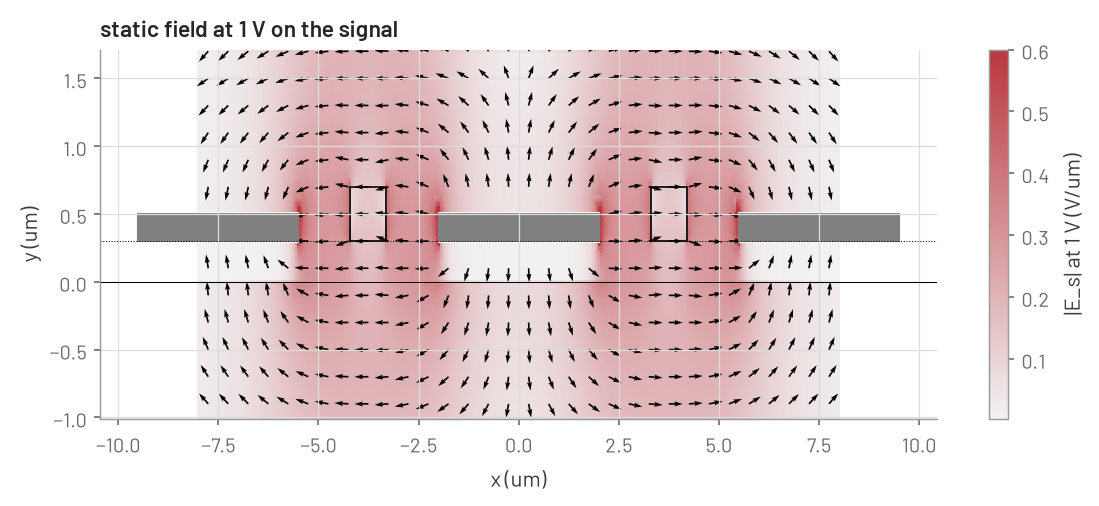

In [4]:
SLAB_THICKNESS = section.static.section_thickness


def grid(x, y, z):
    # The points of the grid x by y (m), at depth z along the guide, row by row.
    X, Y = np.meshgrid(x, y)
    return np.column_stack([X.ravel(), Y.ravel(), np.full(X.size, z)])


def in_metal(points, sec, margin=2e-9):
    # Whether each point lies in (or within a margin of) an electrode.
    x, y = np.abs(points[:, 0]), points[:, 1]
    on_film = (y > 0.3 * um - margin) & (y < 0.5 * um + margin)
    beside = (x < sec.signal_edge + margin) | (x > sec.ground_edge - margin)
    return on_film & beside


def static_field(potential, points, sec, h=1e-9):
    # E_s = -grad V at the points, (n, 3) V/m, from central differences; NaN in metal.
    e = np.full((len(points), 3), np.nan)
    keep = ~in_metal(points, sec)
    p = points[keep]
    for k in range(2):
        step = np.zeros(3)
        step[k] = h
        up, down = potential.at(p + step), potential.at(p - step)
        e[keep, k] = -(np.asarray(up) - np.asarray(down)) / (2 * h)
    e[keep, 2] = 0.0  # nothing varies along the guide
    return e


x = np.linspace(-8, 8, 321) * um
y = np.linspace(-1.0, 1.7, 109) * um
e_s = static_field(potential, grid(x, y, SLAB_THICKNESS / 2), section)
magnitude = np.linalg.norm(e_s, axis=1).reshape(y.size, x.size)
centre = static_field(potential, grid([section.ridge_centre], [0.5 * um], 0.0), section)
print(f"E_s in ridge a's centre: {centre[0, 0] * um:.3f} V/um along x")

fig, ax = plt.subplots(figsize=(9, 3.2))
image = ax.pcolormesh(x / um, y / um, magnitude * um, cmap="gfem_sensitivity", vmax=0.6)
fig.colorbar(image, ax=ax, label="|E_s| at 1 V (V/um)")
every = (slice(4, None, 8), slice(5, None, 10))
X, Y = np.meshgrid(x, y)
# arrows of one length: the field's direction
ex, ey = (e_s[:, k].reshape(X.shape) / magnitude for k in (0, 1))
ax.quiver(X[every] / um, Y[every] / um, ex[every], ey[every], scale=60, width=0.002)
xs, xg, xa, w = (
    v / um
    for v in (
        section.signal_edge,
        section.ground_edge,
        section.ridge_centre,
        section.width,
    )
)
for x0, x1 in ((-xs, xs), (xg, xg + 4), (-xg - 4, -xg)):
    ax.add_patch(plt.Rectangle((x0, 0.3), x1 - x0, 0.2, color="0.5"))
for x0 in (xa, -xa):
    ax.add_patch(plt.Rectangle((x0 - w / 2, 0.3), w, 0.4, fill=False, ec="k", lw=0.8))
ax.axhline(0.0, color="k", lw=0.5)
ax.axhline(0.3, color="k", lw=0.5, ls=":")
ax.set_xlabel("x (um)")
ax.set_ylabel("y (um)")
ax.set_title("static field at 1 V on the signal");

## The mode and the overlap

{py:class}`gfem.PortMode` solves the window's guided modes, numbered from the most
propagating. The modulator uses the TE mode, polarized along $x$, the crystal's $z$:
it sees $n_e$ and the largest coefficient, $r_{33}$. Its TE fraction, the share of
$|E_x|^2$ in $|E_x|^2 + |E_y|^2$ over the window, tells which mode is which:

In [5]:
# cell centres of a 25 nm grid over window a, on the port's face z = 0
xw = section.ridge_centre + np.linspace(-1.7375, 1.7375, 140) * um
yw = np.linspace(-1.1875, 1.6875, 116) * um
window_points = grid(xw, yw, 0.0)
for m in (1, 2):
    found = gfem.solve(window_a, gfem.PortMode("arm", F0, mode=m))
    e = np.abs(np.asarray(found.e_field.at(window_points))[0]) ** 2
    te = e[:, 0].sum() / (e[:, 0] + e[:, 1]).sum()
    print(f"mode {m}: n_eff {float(found.n_eff[0].real):.5f}, TE fraction {te:.3f}")

mode 1: n_eff 1.92489, TE fraction 0.010


mode 2: n_eff 1.90761, TE fraction 0.995


Mode 1 is TM, polarized up the ridge, and mode 2 is the TE mode: $n_\mathrm{eff} =
1.9076$, 99.5 % TE. The page asks for `mode=2`. Check the TE fraction for a section
of your own: with another ridge the order can change.

{py:func}`gfem.electro_optic_shift` weighs, element by element, the mode's field
against the permittivity change the static field causes:

$$
\frac{\partial n_\mathrm{eff}}{\partial V} = \frac{c \varepsilon_0}{4} \,
\mathrm{Re} \int E_0^* \cdot \Delta\varepsilon\, E_0 \, dA, \qquad
\Delta\varepsilon = -\varepsilon\, (r \cdot E_\mathrm{s})\, \varepsilon,
$$

with $E_0$ the mode at 1 W, $E_\mathrm{s}$ the static field at 1 V, and $\varepsilon$
and $r$ rotated from the crystal's axes into the section's frame. The integrand shows
where the shift is earned. Below, it is evaluated on a grid over the crystal of
window a, next to the mode, and summed: the sum is a quadrature of the same
integral, so it should agree with the shift to the grid's resolution.

In [6]:
mode = gfem.solve(window_a, gfem.PortMode("arm", F0, mode=2))
e0 = np.asarray(mode.e_field.at(window_points))[0]  # (points, 3), V/m at 1 W

A = np.asarray(AXES)  # rows: the crystal's x, y, z in the section's frame
EPS = A.T @ np.diag((N_O**2, N_O**2, N_E**2)) @ A
VOIGT = ((0, 0), (1, 1), (2, 2), (1, 2), (0, 2), (0, 1))
r3 = np.zeros((3, 3, 3))
for row, (i, j) in enumerate(VOIGT):
    r3[i, j] = r3[j, i] = np.asarray(R_LN)[row]
r_section = np.einsum("ai,bj,ck,ijk->abc", A.T, A.T, A.T, r3)

xc, half_w = section.ridge_centre, section.width / 2
px, py = window_points[:, 0], window_points[:, 1]
crystal = ((py > 0) & (py < 0.3 * um)) | (
    (np.abs(px - xc) < half_w) & (py >= 0.3 * um) & (py < 0.7 * um)
)
e_static = np.zeros((len(px), 3))
e_static[crystal] = static_field(
    potential, window_points[crystal] + [0, 0, SLAB_THICKNESS / 2], section
)
delta_eps = -np.einsum("ab,bck,pk,cd->pad", EPS, r_section, e_static, EPS)
density = c * epsilon_0 / 4 * np.einsum("pa,pab,pb->p", e0.conj(), delta_eps, e0).real
cell = (xw[1] - xw[0]) * (yw[1] - yw[0])
a = gfem.electro_optic_shift(window_a, potential, port="arm", frequency=F0, mode=2)
print(a)
print(f"the integrand summed on the grid: {density.sum() * cell:.4e} /V")

ElectroOpticShift(port 'arm', mode 2, 1.93414e+14 Hz, n_eff 1.907609, delta_n_eff_per_volt -2.4106e-05 /V, v_pi_l 0.0321497 V m)
the integrand summed on the grid: -2.4137e-05 /V


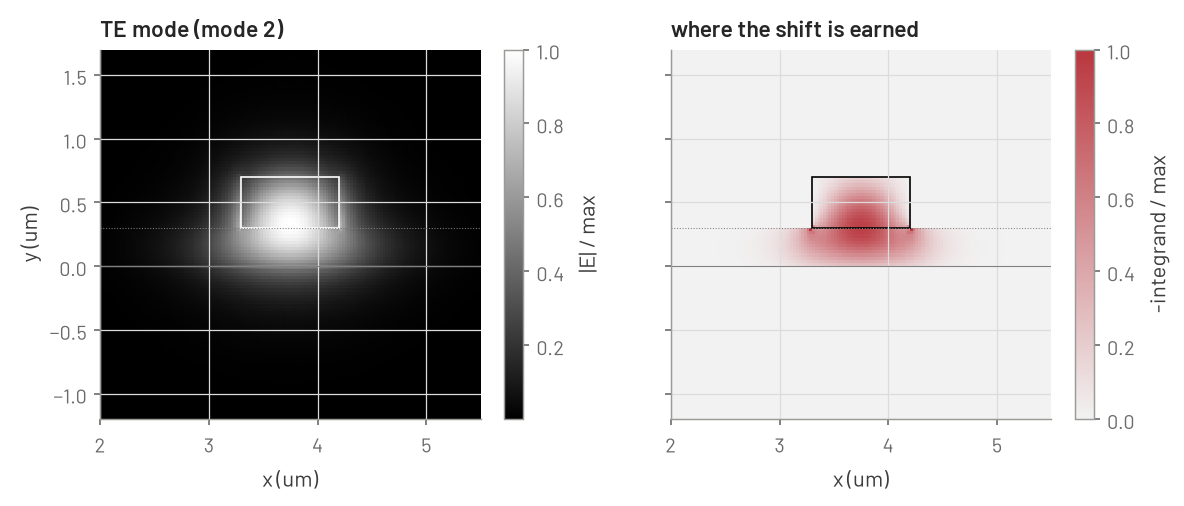

In [7]:
fig, (ax_m, ax_d) = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
shape = (yw.size, xw.size)
mode_e = np.linalg.norm(e0, axis=1).reshape(shape)
image = ax_m.pcolormesh(xw / um, yw / um, mode_e / mode_e.max(), cmap="gray")
fig.colorbar(image, ax=ax_m, label="|E| / max")
ax_m.set_title("TE mode (mode 2)")
work = -density.reshape(shape)
image = ax_d.pcolormesh(xw / um, yw / um, work / work.max(), cmap="gfem_sensitivity")
fig.colorbar(image, ax=ax_d, label="-integrand / max")
ax_d.set_title("where the shift is earned")
for ax in (ax_m, ax_d):
    ax.add_patch(
        plt.Rectangle(
            ((xc - half_w) / um, 0.3),
            2 * half_w / um,
            0.4,
            fill=False,
            ec="w" if ax is ax_m else "k",
            lw=0.8,
        )
    )
    ax.axhline(0.0, color="0.5", lw=0.5)
    ax.axhline(0.3, color="0.5", lw=0.5, ls=":")
    ax.set_xlabel("x (um)")
ax_m.set_ylabel("y (um)");

The sum matches `delta_n_eff_per_volt` to 0.13 %, the grid's quadrature error. The
shift is earned where the mode and the sideways field overlap in the crystal: the
ridge's lower half and the film just beside it. There the mode is strongest, and the
field runs along the film between the electrodes' feet. The cladding above holds
part of the mode but no crystal, so it earns nothing.

## V_π L

Arm b is arm a's mirror image, and its field points the other way: its shift has the
opposite sign. In the push-pull interferometer the two arms' phases subtract, so the
{term}`voltage-length product` of the pair is

$$
V_\pi L = \frac{\lambda}{2\,|s_a - s_b|}, \qquad s = \frac{\partial n_\mathrm{eff}}{\partial V},
$$

half that of one arm when $s_b = -s_a$. `v_pi_l` gives the single arm's.

In [8]:
b = gfem.electro_optic_shift(window_b, potential, port="arm", frequency=F0, mode=2)
s_a, s_b = float(a.delta_n_eff_per_volt), float(b.delta_n_eff_per_volt)
v_pi_l = WAVELENGTH / (2 * abs(s_a - s_b))  # V m
LENGTH = 2e-3  # the paper's electrodes, m
print(f"s_b / s_a = {s_b / s_a:.6f}")
print(
    f"V_pi L per arm: {100 * float(a.v_pi_l):.3f} V cm (a), "
    f"{100 * float(b.v_pi_l):.3f} V cm (b)"
)
print(f"V_pi L push-pull: {100 * v_pi_l:.3f} V cm")
print(f"V_pi over {1e3 * LENGTH:.0f} mm: {v_pi_l / LENGTH:.2f} V")

s_b / s_a = -0.999963
V_pi L per arm: 3.215 V cm (a), 3.215 V cm (b)
V_pi L push-pull: 1.608 V cm
V_pi over 2 mm: 8.04 V


The push-pull pair needs 1.61 V·cm: 8.04 V over the paper's 2 mm. The two arms'
shifts are equal and opposite to $4 \times 10^{-5}$, the difference between two
meshes that are mirror images only up to the mesher.

**Against the bulk estimate.** A uniform field $V/g$ across the gap, acting on a mode
entirely in the crystal, would shift the index by $\tfrac12 n_e^3 r_{33} V/g$. The
ratio of the computed shift to it is the {term}`electro-optic overlap factor`
$\Gamma$, typically 0.3 to 0.7 for such ridges.

**Which coefficients work.** The shift is linear in the tensor, so `jax.grad` with
respect to the four entries gives each one's share of it: $r\, \partial s/\partial r
\,/\, s$, which sum to 1. A {py:obj}`gfem.MaterialField` carries the tensor so that
`jax.grad` reaches it.

In [9]:
gamma = abs(s_a) / (0.5 * N_E**3 * R33 / section.gap)
print(f"Gamma = {gamma:.3f}")


def arm_a_shift(r):
    # Arm a's shift per volt with the tensor built from (r13, r22, r33, r51).
    crystal = gfem.MaterialField(
        eps_r=jnp.array((N_O**2, N_O**2, N_E**2)),
        axes=AXES,
        electro_optic_tensor=tensor_3m(*r),
    )
    window = window_model(section.window_a, crystal)
    shift = gfem.electro_optic_shift(
        window, potential, port="arm", frequency=F0, mode=2
    )
    return shift.delta_n_eff_per_volt


r = jnp.array([R13, R22, R33, R51])
s_value, ds_dr = jax.value_and_grad(arm_a_shift)(r)
shares = np.asarray(r * ds_dr / s_value)
for name, share in zip(("r13", "r22", "r33", "r51"), shares, strict=True):
    print(f"share of {name}: {share:+.4f}")

Gamma = 0.559


share of r13: +0.0190
share of r22: -0.0000
share of r33: +0.9636
share of r51: +0.0174


$\Gamma = 0.56$: the field in the crystal is about half of $V/g$ (the crystal's
static permittivity pushes it out), and part of the mode lies in the oxide. $r_{33}$
earns 96.4 % of the shift. $r_{13}$ (1.9 %) acts on the mode's small vertical
component $E_y$, and $r_{51}$ (1.7 %) through the static field's vertical part,
strongest near the electrodes' feet. $r_{22}$ earns nothing: it needs a field along
the crystal's $y$, the guide's direction, where neither field has a component.

## Against the paper

Wang et al. measured $V_\pi = 9$ V over 2 mm at DC, $V_\pi L = 1.8$ V·cm, on a
push-pull interferometer with this section.

In [10]:
print(f"{'':>20}  {'V_pi L (V cm)':>13}  {'V_pi, 2 mm (V)':>14}")
print(f"{'measured (Wang)':>20}  {1.8:13.2f}  {9.0:14.2f}")
print(f"{'computed (gfem)':>20}  {100 * v_pi_l:13.2f}  {v_pi_l / LENGTH:14.2f}")

                      V_pi L (V cm)  V_pi, 2 mm (V)
     measured (Wang)           1.80            9.00
     computed (gfem)           1.61            8.04


The computed 1.61 V·cm is 11 % below the measured 1.8 V·cm. Several causes act
together, and this page does not separate them:

- **Withheld geometry.** The paper leaves out the sidewall angle, the buried oxide and
  cladding thicknesses and the electrodes' thickness. Vertical sidewalls are the
  largest guess: a leaning ridge has less crystal near the electrodes' feet, where
  the shift is earned.
- **DC against the clamped constants.** The paper measured at DC. The $r_{33}$ and
  static permittivity here are the clamped, high-frequency values, and textbook
  values rather than the film's.

The difference is an observation, inside the ±30 % these unknowns allow, and the page
does not assert it.

## The gap's exact derivative

How fast does the shift change with the gap? {py:func}`gfem.shape.boundary_morph`
moves a named surface of the static mesh along its normal, the rest of the mesh
following, and `jax.grad` differentiates the shift through the move. The shift reads
the static field at fixed points of the window, so the gradient counts both the
potential's change and the static mesh moving under those points.

The gap is moved with the ridge kept centred in it. One morph moves the signal's two
inner walls, another the grounds' inner walls, each by half the move; `boundary_morph`
moves one surface, so the two moves are summed. Each is linear in its parameters, so
their sum is the move of both walls. The ridges' outlines are held (`fixed=`), and
the film's faces, named in the mesh, slide along themselves: the crystal keeps its
shape. A positive parameter grows each electrode, so a move $s$ closes the gap by
$s$.

In [11]:
def gap_closed_by(sec, static, window):
    # Arm a's shift per volt as a function of s (m), the gap closed by s; and n_eff.
    def walls(x0):
        return lambda points: np.abs(np.abs(points[:, 0]) - x0) < 1e-12

    hold = ["ridge_a_s", "ridge_b_s"]
    signal = boundary_morph(
        static, "signal_s", where=walls(sec.signal_edge), fixed=hold
    )
    ground = boundary_morph(
        static, "ground_s", where=walls(sec.ground_edge), fixed=hold
    )

    def shift(s):
        moved = jax.tree.map(
            lambda p, q, p0: p + q - p0,
            signal(s / 2 * jnp.ones(signal.n_params)),
            ground(s / 2 * jnp.ones(ground.n_params)),
            static.mesh,
        )
        v = gfem.solve(static.replace(mesh=moved), DRIVE, options=OPTIONS)
        found = gfem.electro_optic_shift(
            window, v.potential["signal"], port="arm", frequency=F0, mode=2
        )
        return found.delta_n_eff_per_volt, found.n_eff

    return shift


closed_by = gap_closed_by(section, static, window_a)
(s0, _), ds = jax.value_and_grad(closed_by, has_aux=True)(0.0)
h = 2e-9  # m
fd = (float(closed_by(h)[0]) - float(closed_by(-h)[0])) / (2 * h)
ds_dg = -float(ds)  # opening the gap is closing it by a negative s
fd_error = abs(fd / float(ds) - 1)
print(f"(1/s) ds/dg = {ds_dg / float(s0) * um:+.4f} per um of gap")
print(f"dV_pi L/dg = {-100 * v_pi_l * ds_dg / float(s0) * um:+.3f} V cm per um")
print(f"against a central difference at 2 nm: {fd_error:.1e}")

(1/s) ds/dg = -0.2961 per um of gap
dV_pi L/dg = +0.476 V cm per um
against a central difference at 2 nm: 2.2e-05


Opening the gap by 1 µm lowers the shift by 29.6 %, to first order, and raises the
push-pull $V_\pi L$ by 0.48 V·cm. The gradient agrees with a central difference at
2 nm to $2 \times 10^{-5}$. Its cost is one adjoint electrostatic solve, whatever the
number of nodes the move touches.

The window and the static mesh are separate meshes, so the shift jumps slightly when
a point of the window crosses a face of the moving static mesh: it is smooth only
piece by piece, and the gradient is that of the piece the design is on. At 2 nm no
point crosses a face here; a larger step can, and then the difference no longer
measures the gradient. {doc}`../recipes/electro-optic-gradient` shows such a step.

## Co-design of the gap and the width

$V_\pi L$ falls as the gap closes, so it alone drives the electrodes onto the
ridge. Gold next to the light absorbs it. The page asks instead for an
{term}`electrode clearance` set by the mode's own decay. Outside the ridge, the TE
mode decays in the film as $e^{-\kappa |x|}$, with $\kappa = k_0
\sqrt{n_\mathrm{eff}^2 - n_\mathrm{slab}^2}$ and $n_\mathrm{slab}$ the TE index of
the 300 nm film alone. Asking the intensity at the electrode to be $\delta$ of its
value at the ridge's edge gives

$$
g \ge g_\mathrm{min}(w) = w + \frac{\ln(1/\delta)}{\kappa(w)},
$$

with $\delta = 10^{-3}$ (30 dB) here. Width now matters: a wider ridge holds the
mode better (larger $n_\mathrm{eff}$ and $\kappa$), which allows a narrower gap,
but puts less of the mode in the strong field near the electrodes' feet. At Wang's
0.9 µm the rule gives $g_\mathrm{min} = 3.38$ µm, against the paper's 3.5 µm: the
reason for this $\delta$.

In [12]:
def film_index():
    # TE index of the 300 nm film between oxide: the symmetric slab's even mode.
    k0d = 2 * np.pi / WAVELENGTH * 0.3 * um

    def mismatch(n):
        inside, outside = np.sqrt(N_E**2 - n**2), np.sqrt(n**2 - N_OXIDE**2)
        return np.tan(k0d / 2 * inside) - outside / inside

    return brentq(mismatch, N_OXIDE + 1e-9, N_E - 1e-9)


N_SLAB = film_index()
DELTA = 1e-3


def min_gap(width, n_eff):
    # The gap whose electrodes see DELTA of the intensity at the ridge's edges, m.
    kappa = 2 * np.pi / WAVELENGTH * np.sqrt(n_eff**2 - N_SLAB**2)
    return width + np.log(1 / DELTA) / kappa


print(f"n_slab = {N_SLAB:.5f}")
print(f"g_min at w = 0.9 um: {min_gap(0.9 * um, float(a.n_eff)) / um:.3f} um")

n_slab = 1.77933
g_min at w = 0.9 um: 3.378 um


**The loop.** {py:func}`scipy.optimize.minimize` with SLSQP minimises the push-pull
$V_\pi L$ over the gap $g \in [2.5, 6]$ µm and the width $w \in [0.6, 1.5]$ µm under
$g - g_\mathrm{min}(w) \ge 0$, from Wang's $(3.5, 0.9)$ µm. Each evaluation remeshes the
section at $(g, w)$ and solves once. By the mirror symmetry shown above, arm a alone
gives the pair: $V_\pi L = \lambda / (4 |s_a|)$.

- **The gap derivative** is exact, through the summed morphs.
- **The width derivative** is a central difference over two remeshes at $w \pm 20$
  nm. A change of width moves the mode, which the shift holds constant, so no exact
  gradient exists for it. The same two remeshes give $n_\mathrm{eff}(w \pm 20$ nm$)$,
  and with it the constraint's width derivative; its gap derivative is 1.
- **The tolerance.** Remeshing moves every node, so the objective carries noise of
  a few $10^{-4}$ V·cm. SLSQP stops when $V_\pi L$ changes by less than `ftol` and
  the constraint is met to `ftol` (in µm): $2 \times 10^{-3}$ is above that noise. A
  tighter tolerance makes the optimizer chase the noise along the flat bottom.

In [13]:
H = 20e-9  # m, the width step
evaluations = {}


def arm_a(gap, width, *, gradient=False):
    # Arm a's shift per volt and n_eff at (gap, width), remeshed; with d/dgap.
    sec = tfln_section(gap, width)
    st, win = static_model(sec.static), window_model(sec.window_a)
    if gradient:
        (s, n), ds = jax.value_and_grad(gap_closed_by(sec, st, win), has_aux=True)(0.0)
        return float(s), -float(ds), float(n)
    v = gfem.solve(st, DRIVE, options=OPTIONS).potential["signal"]
    shift = gfem.electro_optic_shift(win, v, port="arm", frequency=F0, mode=2)
    return float(shift.delta_n_eff_per_volt), float(shift.n_eff)


def evaluate(x):
    # V_pi L (V cm) and the constraint (um), with their gradients, at x = (g, w) um.
    key = tuple(np.round(x, 9))
    if key not in evaluations:
        g, w = np.asarray(x) * um
        s, ds_dg, n = arm_a(g, w, gradient=True)
        s_up, n_up = arm_a(g, w + H)
        s_down, n_down = arm_a(g, w - H)
        f = 100 * WAVELENGTH / (4 * abs(s))
        df_ds = -f / s
        df = np.array([df_ds * ds_dg, df_ds * (s_up - s_down) / (2 * H)]) * um
        con = (g - min_gap(w, n)) / um
        dcon_dw = -(min_gap(w + H, n_up) - min_gap(w - H, n_down)) / (2 * H)
        evaluations[key] = (f, df, con, np.array([1.0, dcon_dw]))
        print(
            f"g {g / um:.4f} um, w {w / um:.4f} um: V_pi L {f:.4f} V cm, "
            f"constraint {1e3 * con:+.1f} nm"
        )
    return evaluations[key]


start = time.perf_counter()
result = minimize(
    lambda x: evaluate(x)[0],
    x0=[3.5, 0.9],
    jac=lambda x: evaluate(x)[1],
    method="SLSQP",
    bounds=[(2.5, 6.0), (0.6, 1.5)],
    constraints=[
        {
            "type": "ineq",
            "fun": lambda x: evaluate(x)[2],
            "jac": lambda x: evaluate(x)[3],
        }
    ],
    options={"ftol": 2e-3, "maxiter": 10},
)
g_opt, w_opt = result.x
v_pi_l_opt, _, constraint_opt, _ = evaluate(result.x)
print(result.message)
print(f"optimum: g {g_opt:.3f} um, w {w_opt:.3f} um, V_pi L {v_pi_l_opt:.4f} V cm")
print(f"{len(evaluations)} evaluations in {time.perf_counter() - start:.0f} s")

g 3.5000 um, w 0.9000 um: V_pi L 1.6075 V cm, constraint +122.2 nm


g 3.3193 um, w 1.0647 um: V_pi L 1.5047 V cm, constraint -50.6 nm


g 3.3731 um, w 1.0815 um: V_pi L 1.5289 V cm, constraint -0.3 nm


g 3.3869 um, w 1.1402 um: V_pi L 1.5254 V cm, constraint -3.5 nm


g 3.3902 um, w 1.1395 um: V_pi L 1.5270 V cm, constraint +0.0 nm
Optimization terminated successfully
optimum: g 3.390 um, w 1.139 um, V_pi L 1.5270 V cm
5 evaluations in 158 s


SLSQP stops after five evaluations at $g = 3.39$ µm and $w = 1.14$ µm, on the
constraint: 1.527 V·cm, 5 % below the start. The optimum keeps the paper's gap to
within 0.11 µm but widens the ridge by more than a quarter. A wider ridge holds the
mode more tightly, so the clearance allows a narrower gap, and that gain outweighs
the overlap the wider ridge loses. The bottom is flat: the last three evaluations
lie within 0.005 V·cm of each other. Read the result as a design trend, not as a
claim against the paper.

The map below is $V_\pi L$ on a 3 × 3 grid of gaps and widths, one solve each,
interpolated between points. The dashed line is $g_\mathrm{min}(w)$ from each width's
$n_\mathrm{eff}$ (it barely depends on the gap); the region left of it is ruled out.
The path is the optimizer's.

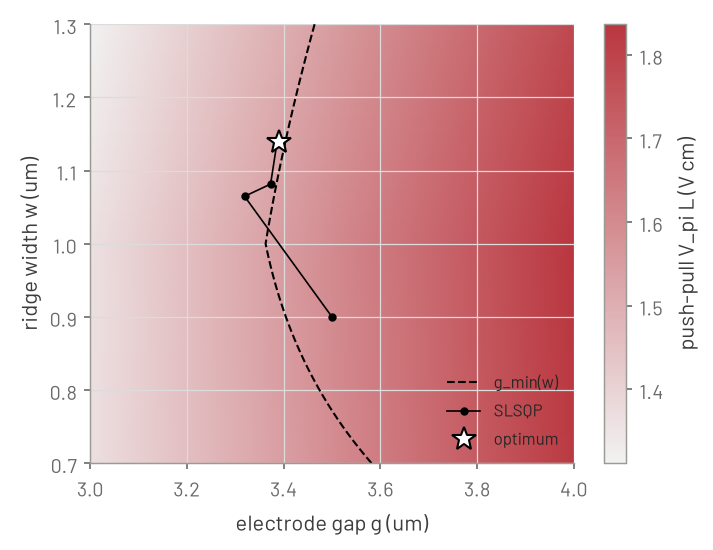

In [14]:
gaps = np.linspace(3.0, 4.0, 3)
widths = np.linspace(0.7, 1.3, 3)
v_map, n_map = np.zeros((3, 3)), np.zeros((3, 3))
for i, w in enumerate(widths):
    for j, g in enumerate(gaps):
        s, n = arm_a(g * um, w * um)
        v_map[i, j], n_map[i, j] = 100 * WAVELENGTH / (4 * abs(s)), n

w_line = np.linspace(widths[0], widths[-1], 61)
g_line = [
    min_gap(w * um, np.interp(w, widths, n_map.mean(axis=1))) / um for w in w_line
]
path = np.array(list(evaluations))

fig, ax = plt.subplots(figsize=(5.2, 3.8))
image = ax.pcolormesh(gaps, widths, v_map, shading="gouraud", cmap="gfem_sensitivity")
fig.colorbar(image, ax=ax, label="push-pull V_pi L (V cm)")
ax.plot(g_line, w_line, "k--", lw=1, label="g_min(w)")
ax.plot(path[:, 0], path[:, 1], "o-", color="k", ms=3, lw=0.8, label="SLSQP")
ax.plot(g_opt, w_opt, "*", color="w", mec="k", ms=12, label="optimum")
ax.set_xlabel("electrode gap g (um)")
ax.set_ylabel("ridge width w (um)")
ax.legend(loc="lower right", fontsize=8);

## Limits

- **A cross-section at DC.** Travelling-wave effects are absent: the match of the
  RF and optical velocities, the electrodes' RF loss, the bandwidth. The static
  permittivity and $r_{33}$ are clamped values; at RF a different set applies.
- **First order in the field.** The mode is held constant. At $V_\pi$ the second
  order changes the shift by about $10^{-6}$ of itself.
- **The optics never see the metal.** The electrodes are excluded volumes: no
  absorption, no coupling to the metal. The clearance rule stands in for their loss.
- **Withheld geometry.** The assumptions table above, with vertical sidewalls the
  largest unknown.
- **The mode's number.** `mode=2` holds for these dimensions only; check the TE
  fraction for yours.
- **Remeshing noise.** Width derivatives over remeshes are noisy at the $10^{-3}$
  level of the objective, which sets the optimizer's tolerance.

## Next

- {doc}`../recipes/electro-optic-phase`: the shift, push-pull and the capacitance per
  length, step by step.
- {doc}`../recipes/electro-optic-gradient`: the gradients with respect to the tensor,
  the static permittivity, the drive and the gap.
- {doc}`../recipes/shape-gradient` and {doc}`../recipes/remesh-and-restart`: shape
  moves, and optimizations that remesh.
- {doc}`../modes-and-ports`: how wave ports number and pick their modes.
- {doc}`heater`: the thermo-optic phase shifter, the same first-order shift driven by
  a temperature rise.
- {py:mod}`gfem.conventions`: the electro-optic tensor's frame and the sign of the
  shift.

The numbers this page relies on, checked: the arms' shifts equal and opposite to
$10^{-4}$, the push-pull $V_\pi L$ at Wang's point (1.61 V·cm), the integrand's sum
against the shift to 1 %, the shares of the tensor summing to 1, $\Gamma$ between 0.3
and 0.7, the gap gradient against its difference at 2 nm to 5 %, and the optimizer
stopped on the constraint, inside the width bounds, below the start.

In [15]:
np.testing.assert_allclose(s_b / s_a, -1.0, atol=1e-4)
np.testing.assert_allclose(100 * v_pi_l, 1.61, atol=0.01)
np.testing.assert_allclose(density.sum() * cell, s_a, rtol=0.01)
np.testing.assert_allclose(shares.sum(), 1.0, atol=1e-9)
np.testing.assert_array_less(0.3, gamma)
np.testing.assert_array_less(gamma, 0.7)
np.testing.assert_array_less(fd_error, 0.05)
np.testing.assert_equal(result.success, True, err_msg=result.message)
np.testing.assert_array_less(-2e-3, constraint_opt)  # um: met to ftol
np.testing.assert_array_less(0.6, w_opt)  # an interior optimum in width
np.testing.assert_array_less(w_opt, 1.5)
np.testing.assert_array_less(v_pi_l_opt, 100 * v_pi_l)
print(f"page run in {time.perf_counter() - tic:.0f} s")

page run in 303 s
